In [1]:
# Librerías necesarias
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from google.colab.patches import cv2_imshow
import os

In [8]:
def buscar_dados(imagen_original):
    # Copiamos la imagen para no modificar la original
    imagen_lineas = imagen_original.copy()

    # Convertir a escala de grises y suavizar
    gris = cv2.cvtColor(imagen_lineas, cv2.COLOR_BGR2GRAY)
    gris_suave = cv2.GaussianBlur(gris, (3, 3), 0)

    # Crear una máscara binaria de ceros (negra) del mismo tamaño que la imagen
    mascara = np.zeros_like(gris_suave)

    # Definir las coordenadas del rectángulo que encierra los dados (Región de Interés - ROI)
    alto, ancho = gris_suave.shape
    ymin, ymax = int(alto * 0.1), int(alto * 0.5)
    xmin, xmax = int(ancho * 0.2), int(ancho * 0.8)

    # Dibujamos un rectángulo blanco (255) en la máscara
    mascara[ymin:ymax, xmin:xmax] = 255

    # Detectar bordes con Canny de forma global
    bordes = cv2.Canny(gris_suave, 50, 230, apertureSize=3)

    # Aplicar la máscara sobre los bordes
    bordes_enmascarados = cv2.bitwise_and(bordes, bordes, mask=mascara)

    # Aplicar la Transformada de Hough Probabilística
    lineas = cv2.HoughLinesP(
        bordes_enmascarados,
        rho=1,
        theta=np.pi / 180,
        threshold=40,
        minLineLength=120,
        maxLineGap=8
    )

    # Dibujar un rectángulo azul para visualizar el área delimitada por la máscara
    cv2.rectangle(imagen_lineas, (xmin, ymin), (xmax, ymax), (255, 0, 0), 4)

    # Dibujar las líneas detectadas (en verde) sobre la imagen
    if lineas is not None:
        for linea in lineas:
            x1, y1, x2, y2 = linea.ravel()
            cv2.line(imagen_lineas, (x1, y1), (x2, y2), (0, 255, 0), 3)
        print(f"Se detectaron {len(lineas)} segmentos de línea recta dentro del área enmascarada.")
    else:
        print("No se detectaron líneas en la región seleccionada.")

    # Retornar la imagen resultante
    return imagen_lineas

In [9]:
def crop_monedas(imagen_original, detalle_monedas, carpeta_salida='monedas_recortadas'):
    # Copiamos la imagen para no modificar la original
    imagen_recortada = imagen_original.copy()

    if detalle_monedas is None:
        print("No hay círculos o monedas para recortar.")
        return

    # Crear la carpeta de salida si no existe
    if not os.path.exists(carpeta_salida):
        os.makedirs(carpeta_salida)
        print(f"Carpeta creada: {carpeta_salida}")

    # Convertir a enteros
    circulos = np.uint16(np.around(detalle_monedas))
    alto, ancho, _ = imagen_recortada.shape

    print(f"--- Guardando recortes de monedas en '{carpeta_salida}' ---")
    for i, circulo in enumerate(circulos[0, :]):
        centro_x, centro_y, radio = circulo[0], circulo[1], circulo[2]

        # Definir los límites del recorte (bounding box cuadrado)
        ymin = max(0, int(centro_y - 1.1 * radio))
        ymax = min(alto, int(centro_y + 1.1 * radio))
        xmin = max(0, int(centro_x - 1.1 * radio))
        xmax = min(ancho, int(centro_x + 1.1 * radio))

        # Realizar el recorte (crop)
        crop = imagen_recortada[ymin:ymax, xmin:xmax]

        # Definir la ruta completa del archivo y guardar
        nombre_archivo = os.path.join(carpeta_salida, f"moneda_{i+1}.png")
        cv2.imwrite(nombre_archivo, crop)
        print(f"Guardada: {nombre_archivo} - Tamaño: {crop.shape[:2]}")

In [ ]:
def buscar_monedas(imagen_original):
    # Copiamos la imagen para no modificar la original
    imagen_circulos = imagen_original.copy()

    # Convertir a escala de grises
    gris = cv2.cvtColor(imagen_circulos, cv2.COLOR_BGR2GRAY)

    # Aplicar un desenfoque Gaussiano más fuerte para eliminar ruido
    gris_suave = cv2.medianBlur(gris, 7)

    # Aplicar la Transformada de Hough para Círculos
    circulos = cv2.HoughCircles(
        gris_suave,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=50, # Distancia mínima en píxeles que debe existir entre los centros de dos círculos detectados
        param1=50, # Es el umbral superior que utiliza el detector de bordes Canny 
        param2=40, # Umbral de votos del acumulador necesario para confirmar el centro de un círculo
        minRadius=140, # Radio mínimo en píxeles que debe tener un círculo para ser aceptado
        maxRadius=176 # Radio máximo en píxeles permitido para la detección
    )

    # Dibujar los círculos detectados
    if circulos is not None:
        # Convertir las coordenadas y los radios a enteros
        circulos = np.uint16(np.around(circulos))

        for i, circulo in enumerate(circulos[0, :]):
            centro_x, centro_y, radio = int(circulo[0]), int(circulo[1]), int(circulo[2])
            # Dibujar el contorno del círculo en verde
            cv2.circle(imagen_circulos, (centro_x, centro_y), radio, (0, 255, 0), 3)
            # Dibujar el centro del círculo en rojo
            cv2.circle(imagen_circulos, (centro_x, centro_y), 3, (0, 0, 255), 4)

            # Coordenadas para ubicar el texto dentro del círculo
            texto_x = centro_x - int(radio * 0.5)
            texto_y_moneda = centro_y - int(radio * 0.2)
            texto_y_radio = centro_y + int(radio * 0.2)

            # Colocar texto Número de moneda
            cv2.putText(imagen_circulos, f"Moneda {i + 1}", (texto_x, texto_y_moneda),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
            # Colocar texto Radio del círculo
            cv2.putText(imagen_circulos, f"Radio: {radio}", (texto_x, texto_y_radio),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
            print(f"Moneda {i + 1} - Radio: {radio}")

        print(f"Se detectaron {len(circulos[0])} monedas/círculos.")
    else:
        print("No se detectaron círculos con los parámetros actuales.")

    # Retornar la imagen resultante y la información de los círculos detectados
    return imagen_circulos, circulos

--- Buscando Monedas (Círculos) ---
Moneda 1 - Radio: 175
Moneda 2 - Radio: 161
Moneda 3 - Radio: 164
Moneda 4 - Radio: 166
Moneda 5 - Radio: 163
Moneda 6 - Radio: 162
Moneda 7 - Radio: 175
Moneda 8 - Radio: 162
Moneda 9 - Radio: 142
Moneda 10 - Radio: 141
Moneda 11 - Radio: 144
Moneda 12 - Radio: 141
Moneda 13 - Radio: 142
Moneda 14 - Radio: 144
Moneda 15 - Radio: 141
Moneda 16 - Radio: 145
Moneda 17 - Radio: 141
Se detectaron 17 monedas/círculos.


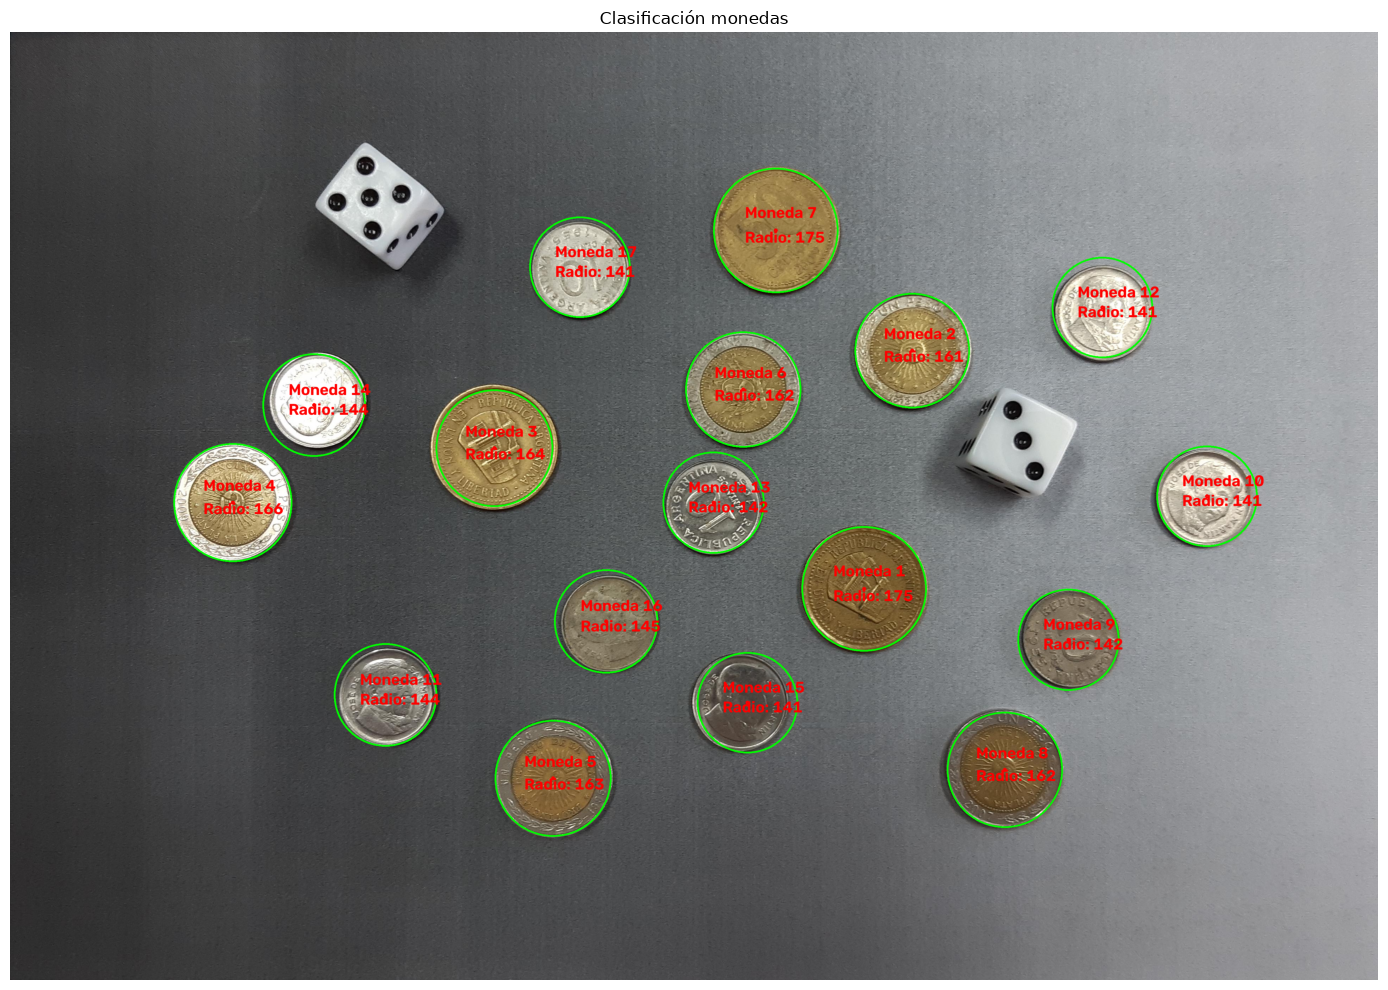

--- Guardando recortes de monedas en './crop_monedas' ---
Guardada: ./crop_monedas\moneda_1.png - Tamaño: (385, 385)
Guardada: ./crop_monedas\moneda_2.png - Tamaño: (355, 355)
Guardada: ./crop_monedas\moneda_3.png - Tamaño: (361, 361)
Guardada: ./crop_monedas\moneda_4.png - Tamaño: (365, 365)
Guardada: ./crop_monedas\moneda_5.png - Tamaño: (359, 359)
Guardada: ./crop_monedas\moneda_6.png - Tamaño: (357, 357)
Guardada: ./crop_monedas\moneda_7.png - Tamaño: (385, 385)
Guardada: ./crop_monedas\moneda_8.png - Tamaño: (357, 357)
Guardada: ./crop_monedas\moneda_9.png - Tamaño: (313, 313)
Guardada: ./crop_monedas\moneda_10.png - Tamaño: (311, 311)
Guardada: ./crop_monedas\moneda_11.png - Tamaño: (317, 317)
Guardada: ./crop_monedas\moneda_12.png - Tamaño: (311, 311)
Guardada: ./crop_monedas\moneda_13.png - Tamaño: (313, 313)
Guardada: ./crop_monedas\moneda_14.png - Tamaño: (317, 317)
Guardada: ./crop_monedas\moneda_15.png - Tamaño: (311, 311)
Guardada: ./crop_monedas\moneda_16.png - Tamaño: (3

In [12]:
def main():
    #ruta_imagen = '/content/drive/MyDrive/Colab Notebooks/PDI/TP_2'
    imagen = cv2.imread('./monedas.jpg')

    if imagen is None:
        print("Error: No se pudo cargar la imagen para el proceso principal.")
        return

    print("--- Buscando Monedas (Círculos) ---")
    imagen_monedas, detalle_monedas = buscar_monedas(imagen)
    # Convertimos la imagen de BGR a RGB para mostrarla correctamente con matplotlib
    imagen_monedas = cv2.cvtColor(imagen_monedas, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(30, 10))
    plt.imshow(imagen_monedas)
    plt.title('Clasificación monedas')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


    # Guardamos el crop de cada moneda para realizar un análisis posterior más preciso con clasificar_monedas()
    crop_monedas(imagen, detalle_monedas, './crop_monedas')

    # Clasificamos las monedas por su diámetro y realizamos un conteo
    # radio  <=  145      - Valor: 10 centavos
    # 145 >  radio > 170  - Valor: 1 peso
    # radio >= 170        - Valor: 50 centavos
    # Creamos un dataframe con: Moneda N°, Diámetro, Valor
    if detalle_monedas is not None:
        datos_monedas = []
        for i in range(1, len(detalle_monedas[0]) + 1):
            radio = detalle_monedas[0][i-1][2]
            diametro = 2 * radio

            if radio <= 145:
                valor = "10 centavos"
            elif 145 < radio < 170:
                valor = "1 peso"
            else:
                valor = "50 centavos"

            datos_monedas.append({
                'moneda': i,
                'diametro': diametro,
                'valor': valor
            })

        df = pd.DataFrame(datos_monedas)
        print(df)
        print(f"\nConteo de las monedas encontradas:")
        print(df['valor'].value_counts())




    """
    # Iteramos sobre cada uno de los crops y guardamos la información de cada diámetro encontrado en un dataframe
    if detalle_monedas is not None:
        for i in range(1, len(detalle_monedas[0]) + 1):
            crop = cv2.imread(f'{ruta_imagen}/crop_monedas/moneda_{i}.png')
            if crop is not None:
                _, valor = buscar_monedas(crop)
                print(valor)
                clasificar_monedas(crop)
    """


    """
    print("\n--- Buscando Dados (Líneas) ---")
    resultado_dados = buscar_dados(imagen)
    cv2_imshow(resultado_dados)
    """

# Ejecutar el flujo principal
if __name__ == '__main__':
    main()

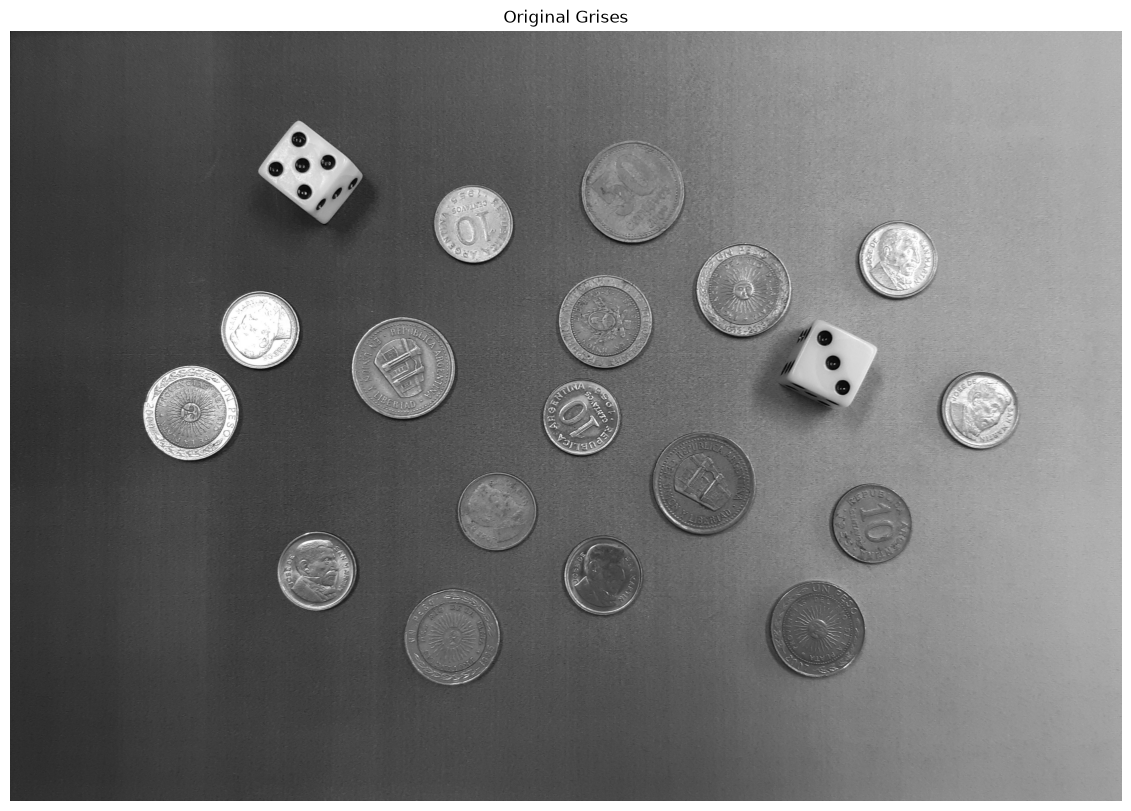

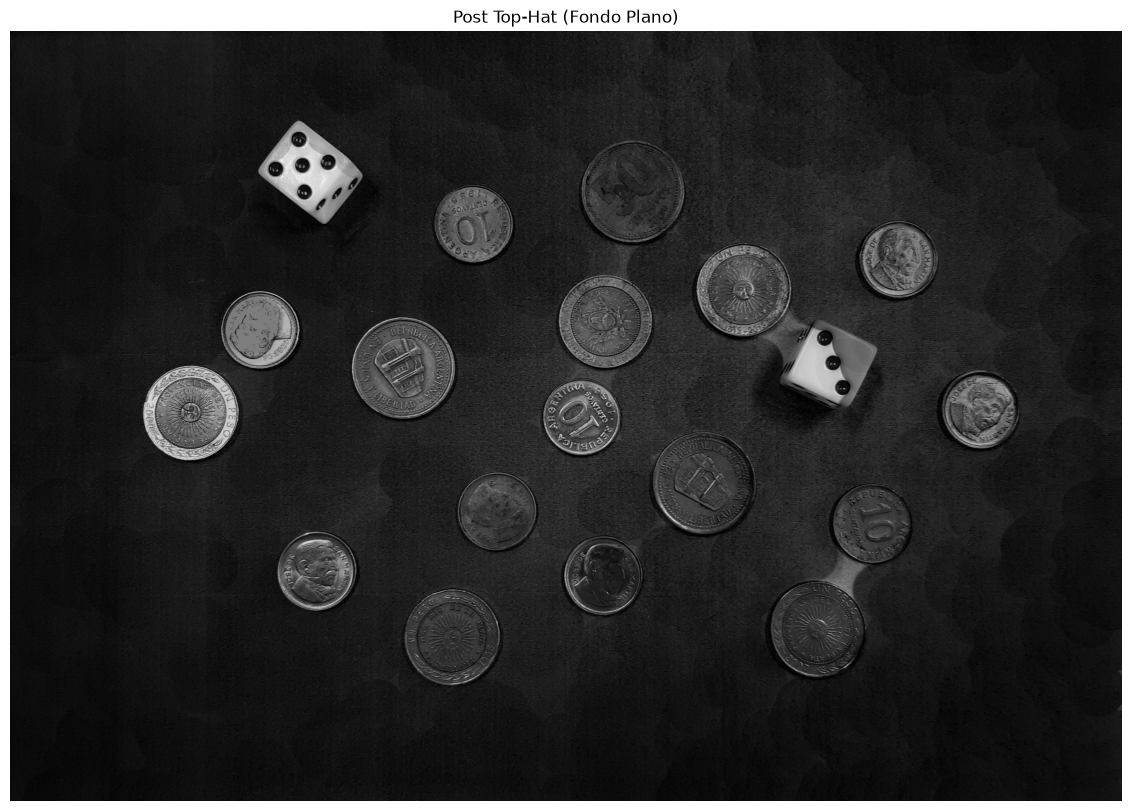

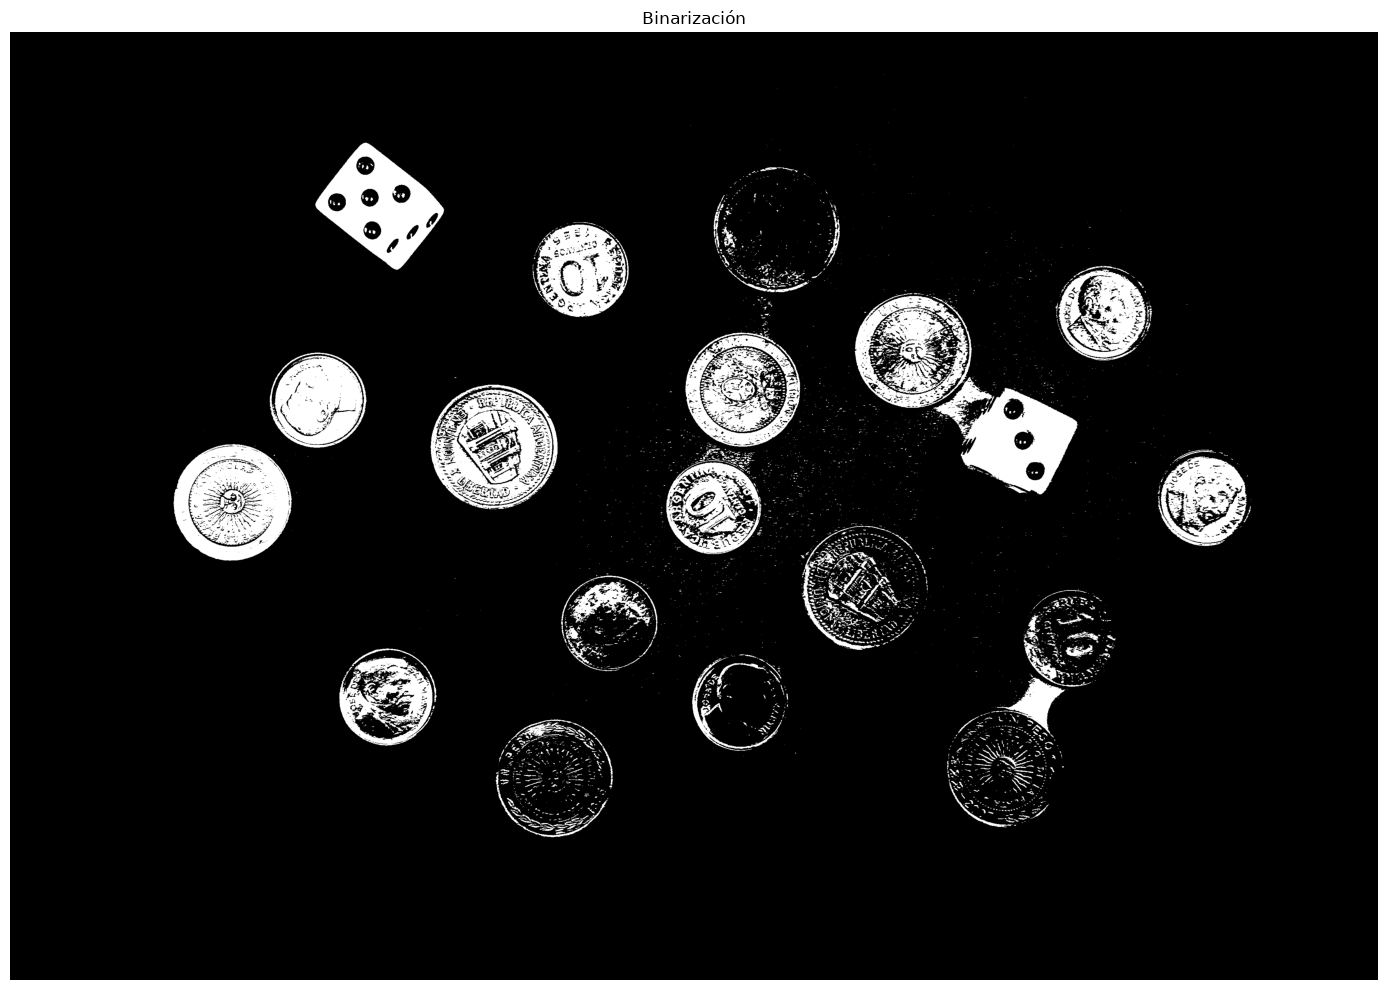

In [ ]:
# Prueba de la operación Top-Hat para resaltar detalles en la
# imagen con iluminación desigual
# 1. Cargar la imagen en escala de grises
img = cv2.imread('./monedas.jpg', cv2.IMREAD_GRAYSCALE)

# 2. Definir un kernel grande (adecuado para los dados)
k = 185
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

# 3. Aplicar Top-Hat para aislar los objetos claros del fondo
top_hat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

# 4. Umbralizado Otsu sobre el Top-Hat para binarizar perfectamente
# Como el fondo ahora es negro, Otsu debe funcionar bien
_, img_binaria = cv2.threshold(top_hat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Visualizar el paso a paso
plt.figure(figsize=(30, 10))

plt.imshow(img, cmap='gray')
plt.title('Original Grises')
plt.axis('off')
plt.show()

plt.figure(figsize=(30, 10))
plt.imshow(top_hat, cmap='gray')
plt.title('Post Top-Hat (Fondo Plano)')
plt.axis('off')
plt.show()

plt.figure(figsize=(30, 10))
plt.imshow(img_binaria, cmap='gray')
plt.title('Binarización')
plt.axis('off')

plt.tight_layout()
plt.show()


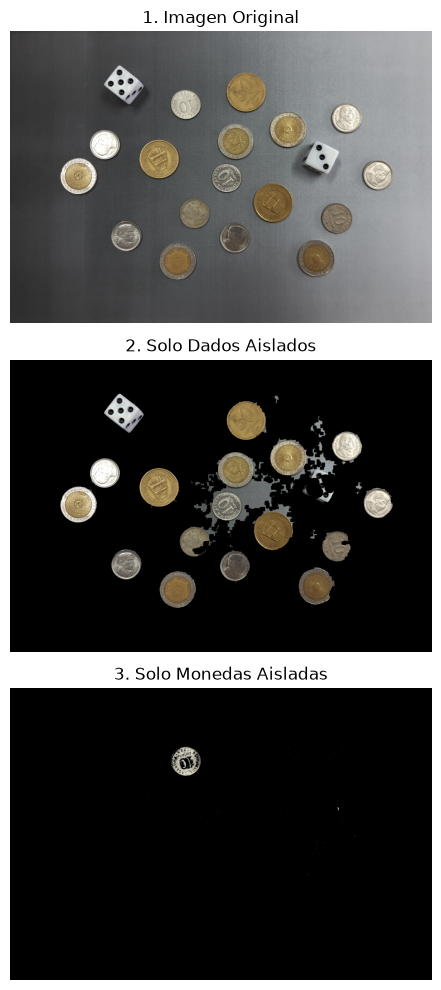

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar imagen y limpiar el fondo con el Top-Hat que ya calculamos
img = cv2.imread('./monedas.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Top-Hat para aplanar el fondo gris
kernel_size = 87
kernel_th = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
top_hat = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, kernel_th)

# Binarizar el resultado del Top-Hat
_, thresh = cv2.threshold(top_hat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# =====================================================================
# 2. SEPARACIÓN DE LOS DADOS (CORREGIDO PARA DADOS ROTADOS)
# =====================================================================
# Rellenamos los puntos de los dados aplicando una Clausura morfológica
kernel_dice = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel_dice)

# Encontramos los contornos externos
contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Crear máscara vacía para los dados
mask_dados = np.zeros_like(gray)

for cnt in contours:
    area = cv2.contourArea(cnt)
    
    # Filtro por tamaño (ambos dados son medianos, mayores a 1000 píxeles)
    if area > 1000:
        # Calcular el perímetro del contorno
        perimetro = cv2.arcLength(cnt, True)
        
        if perimetro > 0:
            # Fórmula matemática de Circularidad: (4 * pi * Área) / (Perímetro^2)
            circularidad = (4 * np.pi * area) / (perimetro ** 2)
            
            # EXPLICACIÓN: 
            # Una moneda (círculo) tiene una circularidad de ~0.9 a 1.0
            # Un dado (cuadrado) tiene una circularidad mucho menor (~0.7 a 0.82)
            if circularidad < 0.84:
                cv2.drawContours(mask_dados, [cnt], -1, 255, -1)

# Extracción física de los dados
dados_aislados = cv2.bitwise_and(img, img, mask=mask_dados)


# 3. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(30, 10))

plt.subplot(2, 1, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('1. Imagen Original')
plt.axis('off')

plt.subplot(2, 1, 2)
plt.imshow(cv2.cvtColor(dados_aislados, cv2.COLOR_BGR2RGB))
plt.title('2. Dados Aislados')
plt.axis('off')


plt.tight_layout()
plt.show()
